In [1]:

# CodeOrbit Tech Internship
# Task 2: Exploratory Data Analysis (EDA)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv(
    r"D:\CodeOrbit_Titanic_Cleaned.csv"
)

# Basic inspection
print("Dataset loaded successfully!")
print("Number of passengers:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of passengers: 891
Number of columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


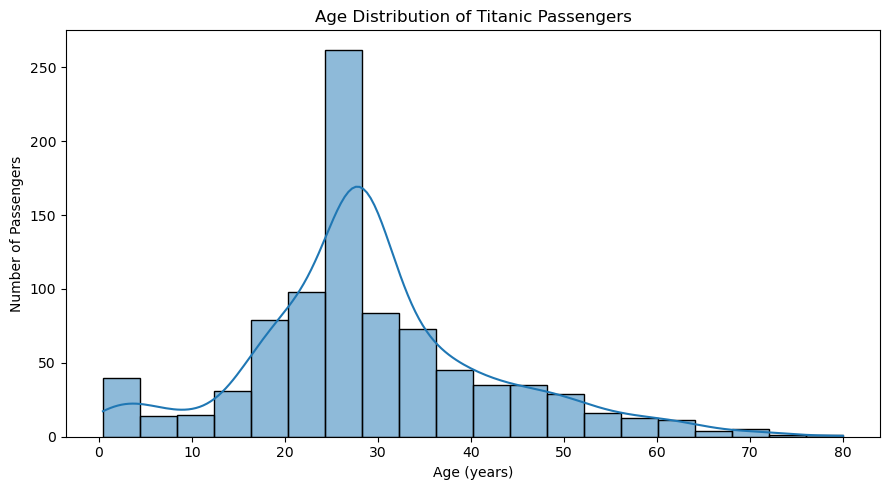

In [2]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


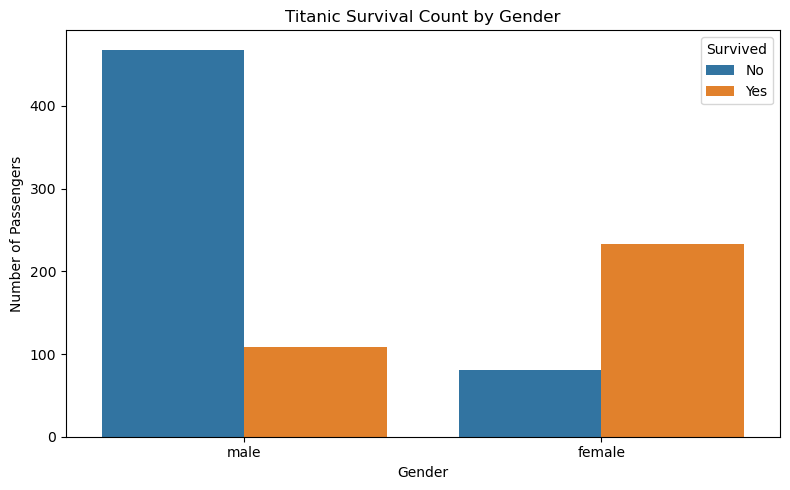

In [3]:

# Survival count by gender

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Sex",
    hue="Survived"
)

plt.title("Titanic Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.tight_layout()
plt.show()


Survival Rate by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


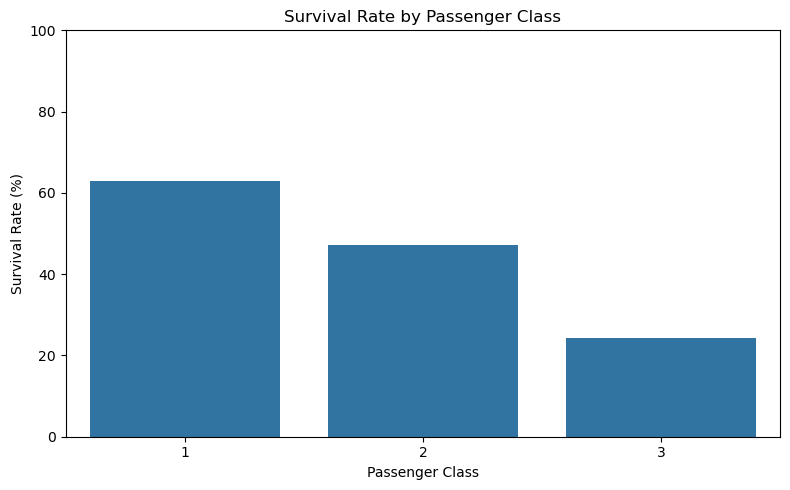

In [4]:

# Calculate survival rate for each passenger class

class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival Rate by Passenger Class:")
print(class_survival.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_survival.index,
    y=class_survival.values
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


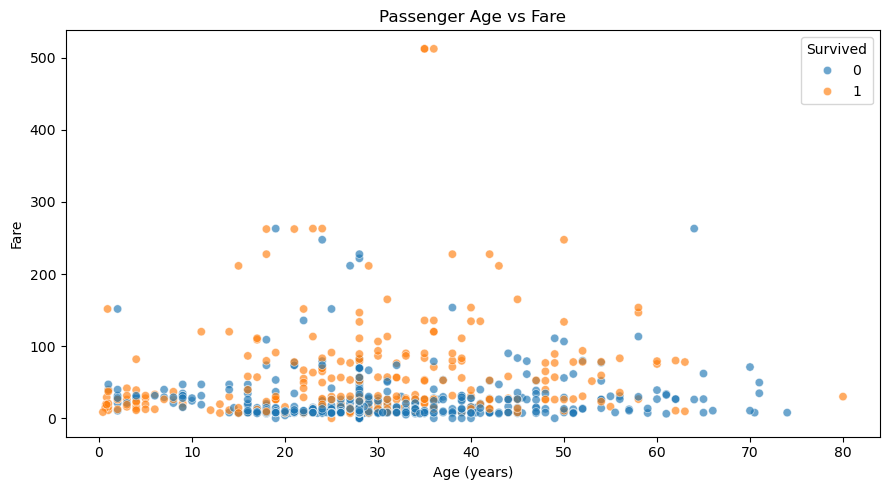

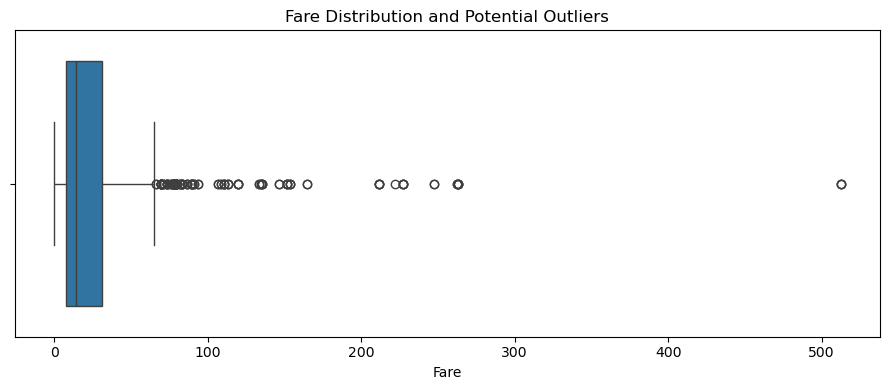

In [5]:

# Relationship between age and fare

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Fare",
    hue="Survived",
    alpha=0.65
)

plt.title("Passenger Age vs Fare")
plt.xlabel("Age (years)")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

# Fare outlier inspection
plt.figure(figsize=(9, 4))

sns.boxplot(data=df, x="Fare")

plt.title("Fare Distribution and Potential Outliers")
plt.xlabel("Fare")
plt.tight_layout()
plt.show()


In [6]:

# Task 2: Key EDA Findings

print("1. SURVIVAL RATE")
print(f"Overall survival rate: {df['Survived'].mean() * 100:.2f}%")

print("\n2. SURVIVAL RATE BY GENDER")
gender_rate = df.groupby("Sex")["Survived"].mean() * 100
print(gender_rate.round(2))

print("\n3. SURVIVAL RATE BY PASSENGER CLASS")
class_rate = df.groupby("Pclass")["Survived"].mean() * 100
print(class_rate.round(2))

print("\n4. AGE SUMMARY")
print(df["Age"].describe().round(2))

print("\n5. FARE OUTLIER CHECK")
q1 = df["Fare"].quantile(0.25)
q3 = df["Fare"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

print("Upper outlier threshold:", round(upper_limit, 2))
print("Potential high-fare outliers:", int((df["Fare"] > upper_limit).sum()))


1. SURVIVAL RATE
Overall survival rate: 38.38%

2. SURVIVAL RATE BY GENDER
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

3. SURVIVAL RATE BY PASSENGER CLASS
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

4. AGE SUMMARY
count    891.00
mean      29.36
std       13.02
min        0.42
25%       22.00
50%       28.00
75%       35.00
max       80.00
Name: Age, dtype: float64

5. FARE OUTLIER CHECK
Upper outlier threshold: 65.63
Potential high-fare outliers: 116


In [7]:

findings = pd.DataFrame({
    "Gender": gender_rate.index,
    "Survival_Rate_Percent": gender_rate.values
})

findings.to_csv("CodeOrbit_Task2_Gender_Findings.csv", index=False)

class_findings = pd.DataFrame({
    "Passenger_Class": class_rate.index,
    "Survival_Rate_Percent": class_rate.values
})

class_findings.to_csv("CodeOrbit_Task2_Class_Findings.csv", index=False)

print("EDA findings saved successfully!")


EDA findings saved successfully!
